In [1]:
import os
import pandas as pd
import numpy as np

In [2]:
# microwells to delete because no correspondance between video and nomenclature
# (the nomenclature name is wrong)
bad_mw = ["TR9-C01_tile008_a4",\
          "(HPC_3000)_tile009_d1"]
# path in which we save the figures for the paper   
path_save = r"Figures"
os.makedirs(path_save, exist_ok=True)
# filtering index
name_index = "Osc_index-9"
# for plotting
label_map = {
    'HSC_2000': 'HSC',
    'HPC_3000': 'CD34+', #'HPC'
    'MPP_epp':  'MPP',
    'LMPP_epp': 'LMPP',
    'TR1-A01':  'BMS-265246',
    'TR3-A03':  'Venetoclax',
    'TR5-B04':  'JQ-1',
    'TR7-B02':  'Palbociclib',
    'TR9-C01':  'Control',
}

datatype_groups = {
    'Cell Line': ['TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01'],
    'Cord Blood': ['HSC_2000', 'MPP_epp', 'LMPP_epp', 'HPC_3000']}

# Marker map for the 9 conditions
marker_map = {
    # Cell Lines (Group 1)
    'TR1-A01': 'D',  # Diamond
    'TR3-A03': 'P',  # Plus
    'TR5-B04': '*',  # Star
    'TR7-B02': 'X',  # X
    'TR9-C01': 'h',  # Hexagon
    
    # Cord Blood (Group 2)
    #'HSC_2000': 's', # Square
    'HPC_3000': 'o', # Circle
    #'MPP_epp':  'v', # Triangle down
    #'LMPP_epp': '^', # Triangle up

}


Load groundtruth

In [3]:
# path for results and groundtruth
cellpose_results = r"..\groundtruth\Cellpose" 
gt_path = "../groundtruth"

# extract the groundtruths in a dataframe
name_gt = "MB_Groundtruths_corrected.xlsx"
sheet_names = ["MB_250807", "MB_251003"]
dfs = []
for sheet_name in sheet_names: # read each sheet
    df = pd.read_excel(os.path.join(gt_path, name_gt), sheet_name=sheet_name)
    dfs.append(df)
df_gt = pd.concat(dfs, axis=1) # concatenate by column
df_gt.columns = df_gt.iloc[0] # the first row becomes the header column name
df_gt = df_gt[1:].reset_index(drop=True) # take only the values
# drop the bad nomenclature wells
df_gt = df_gt.drop(bad_mw, axis=1)

In [4]:
# drop HSC, LMPP, MPP
print(len(df_gt.columns))
pattern_to_drop = r'^\((HSC_2000|LMPP_epp|MPP_epp)\)'
df_gt = df_gt.drop(columns=df_gt.filter(regex=pattern_to_drop).columns)
print(len(df_gt.columns))

93
63


In [5]:
from functions.functions_segmentation_benchmark import obtain_output_inference
df_cellpose_nocorrection=obtain_output_inference(cellpose_results, col_name="Output YOLO")
df_cellpose_wtcorrection=obtain_output_inference(cellpose_results, col_name="Correction")

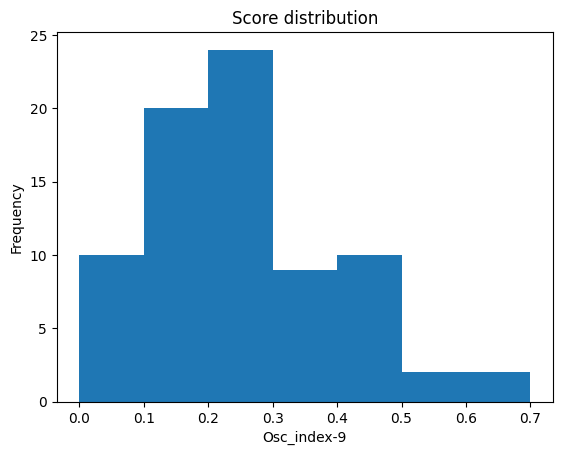

In [6]:
# select
from notebook.functions.functions_segmentation_benchmark import filter_score

df_scores, scores, name_columns_good = filter_score(cellpose_results, thresh_score=0.2, name_index="Osc_index-9")
df_cellpose_nocorrection = df_cellpose_nocorrection[name_columns_good]
df_cellpose_wtcorrection = df_cellpose_wtcorrection[name_columns_good]


In [7]:
import numpy as np
from src.visiowell_pipeline.routines.functions_postcorrection import algorithm_change_point_detection

def correct_with_stat(signal, change_points, stat="mlv"):
    """Flatten each segment using the chosen statistic."""
    signal = np.asarray(signal, dtype=float)
    cps = sorted(set(int(c) for c in change_points))
    if cps[-1] != len(signal):          # ruptures normally includes len(signal)
        cps.append(len(signal))

    out = np.empty_like(signal)
    start = 0
    for end in cps:
        seg = signal[start:end]
        vals, counts = np.unique(seg, return_counts=True)
        mode = vals[np.argmax(counts)]  # smallest value on ties, like scipy
        median, mean = np.median(seg), np.mean(seg)

        if stat == "mode":
            v = mode
        elif stat == "median":
            v = np.round(median)
        elif stat == "mean":
            v = np.round(mean)
        elif stat == "mlv":
            v = np.round((mode + median + mean) / 3)
        else:
            raise ValueError(stat)

        out[start:end] = v
        start = end
    return out


def run_all_variants(df_raw, which_algorithm="pelt", which_model="l2", pen=2):
    stats = ["mode", "median", "mean", "mlv"]
    results = {s: {} for s in stats}
    for well in df_raw.columns:
        signal = df_raw[well].dropna().to_numpy(dtype=float)
        # same call used in correction_CPD (flag_first_correction=0 -> raw signal)
        cps = algorithm_change_point_detection(signal, which_algorithm, which_model, pen)
        for s in stats:
            results[s][well] = correct_with_stat(signal, cps, s)
    return results

results = run_all_variants(df_cellpose_nocorrection)

In [8]:
# check that the results are the same as in the reference
df_mlv = pd.DataFrame({w: pd.Series(v) for w, v in results["mlv"].items()})
df_ref = df_cellpose_wtcorrection

# same wells?
only_mine = set(df_mlv.columns) - set(df_ref.columns)
only_ref  = set(df_ref.columns) - set(df_mlv.columns)
print("Wells only in my version:", only_mine)
print("Wells only in reference:", only_ref)

rows = []
for w in df_mlv.columns.intersection(df_ref.columns):
    a = df_mlv[w].dropna().to_numpy(dtype=float)
    b = df_ref[w].dropna().to_numpy(dtype=float)
    if a.shape != b.shape:
        rows.append({"well": w, "len_mine": len(a), "len_ref": len(b),
                     "n_diff": None, "max_abs_diff": None})
        continue
    diff = a != b
    rows.append({"well": w, "len_mine": len(a), "len_ref": len(b),
                 "n_diff": int(diff.sum()),
                 "max_abs_diff": float(np.abs(a - b).max())})

cmp = pd.DataFrame(rows)
n_wells = len(cmp)
n_identical = (cmp["n_diff"] == 0).sum()
print(f"{n_identical}/{n_wells} wells identical")
print(cmp[cmp["n_diff"] != 0].sort_values("n_diff", ascending=False).head(20))

Wells only in my version: set()
Wells only in reference: set()
30/30 wells identical
Empty DataFrame
Columns: [well, len_mine, len_ref, n_diff, max_abs_diff]
Index: []


In [9]:
import re

variants = {
    "No correction": df_cellpose_nocorrection,
    **{s.upper(): pd.DataFrame({w: pd.Series(v) for w, v in results[s].items()})
       for s in ["mode", "median", "mean", "mlv"]},
}

# key = "<condition>_<tile>_<well>", e.g. "(HPC_3000)_tile008_e2" or "TR1-A01_tile003_b2"
pat = re.compile(r'(\([A-Za-z0-9_]+\)|TR\d+-[A-Z]\d+)_(tile\d+_[a-z]\d)')

def make_key(name):
    m = pat.search(str(name))
    return f"{m.group(1)}_{m.group(2)}" if m else None

# ---- ground truth: drop 'Time', check duplicates, map to key
gt = df_gt.drop(columns=[c for c in df_gt.columns if c == "Time"])
gt_keys = pd.Series([make_key(c) for c in gt.columns], index=range(len(gt.columns)))

print("GT columns without a valid key (bad nomenclature):")
print([c for c, k in zip(gt.columns, gt_keys) if k is None])

dup = gt_keys[gt_keys.duplicated(keep=False) & gt_keys.notna()]
print("Duplicated GT keys:", dup.unique().tolist())

# keep first occurrence of duplicates (check that they are really identical!)
gt_clean = gt.iloc[:, [i for i, k in enumerate(gt_keys) if k is not None]]
gt_clean.columns = [k for k in gt_keys if k is not None]
gt_clean = gt_clean.loc[:, ~gt_clean.columns.duplicated()]

# ---- predictions: rename columns to the same key
def rekey(df):
    out = df.copy()
    out.columns = [make_key(c) for c in df.columns]
    assert out.columns.notna().all() and not out.columns.duplicated().any()
    return out

variants_k = {name: rekey(df) for name, df in variants.items()}

# ---- compare
pred_keys = set(variants_k["MLV"].columns)
gt_set = set(gt_clean.columns)
common = sorted(pred_keys & gt_set)

print(f"\nCommon wells: {len(common)}")
print("In predictions only:", sorted(pred_keys - gt_set))
print("In GT only:", sorted(gt_set - pred_keys))

GT columns without a valid key (bad nomenclature):
['TR9_003_a1', 'TR9_159_b1', 'TR9_041_a2', 'TR9_022_b2', 'TR9_120_b2', 'TR9_082_b3', 'TR9_061_b4', 'TR9_103_c1', 'TR9_139_d2']
Duplicated GT keys: ['TR7-B02_tile005_a3']

Common wells: 22
In predictions only: ['(HPC_3000)_tile009_d1', '(HSC_2000)_tile072_b3', '(HSC_2000)_tile104_a3', '(LMPP_epp)_tile057_a4', '(MPP_epp)_tile035_b2', '(MPP_epp)_tile054_b3', '(MPP_epp)_tile083_c4', 'TR9-C01_tile008_a4']
In GT only: ['(HPC_3000)_tile021_d3', '(HPC_3000)_tile056_d1', '(HPC_3000)_tile058_b3', '(HPC_3000)_tile097_b4', '(HPC_3000)_tile100_b1', 'TR1-A01_tile003_b2', 'TR1-A01_tile051_a1', 'TR1-A01_tile068_b4', 'TR1-A01_tile069_d1', 'TR1-A01_tile147_b4', 'TR1-A01_tile176_b4', 'TR3-A03_tile004_a1', 'TR3-A03_tile057_a2', 'TR3-A03_tile085_a2', 'TR3-A03_tile130_c1', 'TR3-A03_tile133_d2', 'TR3-A03_tile153_c1', 'TR3-A03_tile153_c2', 'TR3-A03_tile180_b2', 'TR5-B04_tile113_b2', 'TR5-B04_tile155_c4', 'TR5-B04_tile156_a2', 'TR5-B04_tile157_c2', 'TR5-B04_ti

In [10]:
from functions.functions_segmentation_benchmark import obtain_performances

perf = {name: obtain_performances(df, df_gt, "nine") for name, df in variants.items()}

def to_series(res, field="mean_error"):
    # re-key by the short key so it matches `common`
    s = pd.Series({make_key(col): r[field] for col, r in res.items()})
    return s[s.index.isin(common)]

order = ["No correction", "MODE", "MEDIAN", "MEAN", "MLV"]
mae8 = pd.DataFrame({name: to_series(res) for name, res in perf.items()})
mae8 = mae8[order]                       # No correction, MODE, MEDIAN, MEAN, MLV
print(len(mae8), "wells")
print(mae8.agg(["mean", "std"]).T.round(4))



No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile104_a3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(LMPP_epp)_tile057_a4_LMPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile035_b2_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile054_b3_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile083_c4_MPP_epp_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match

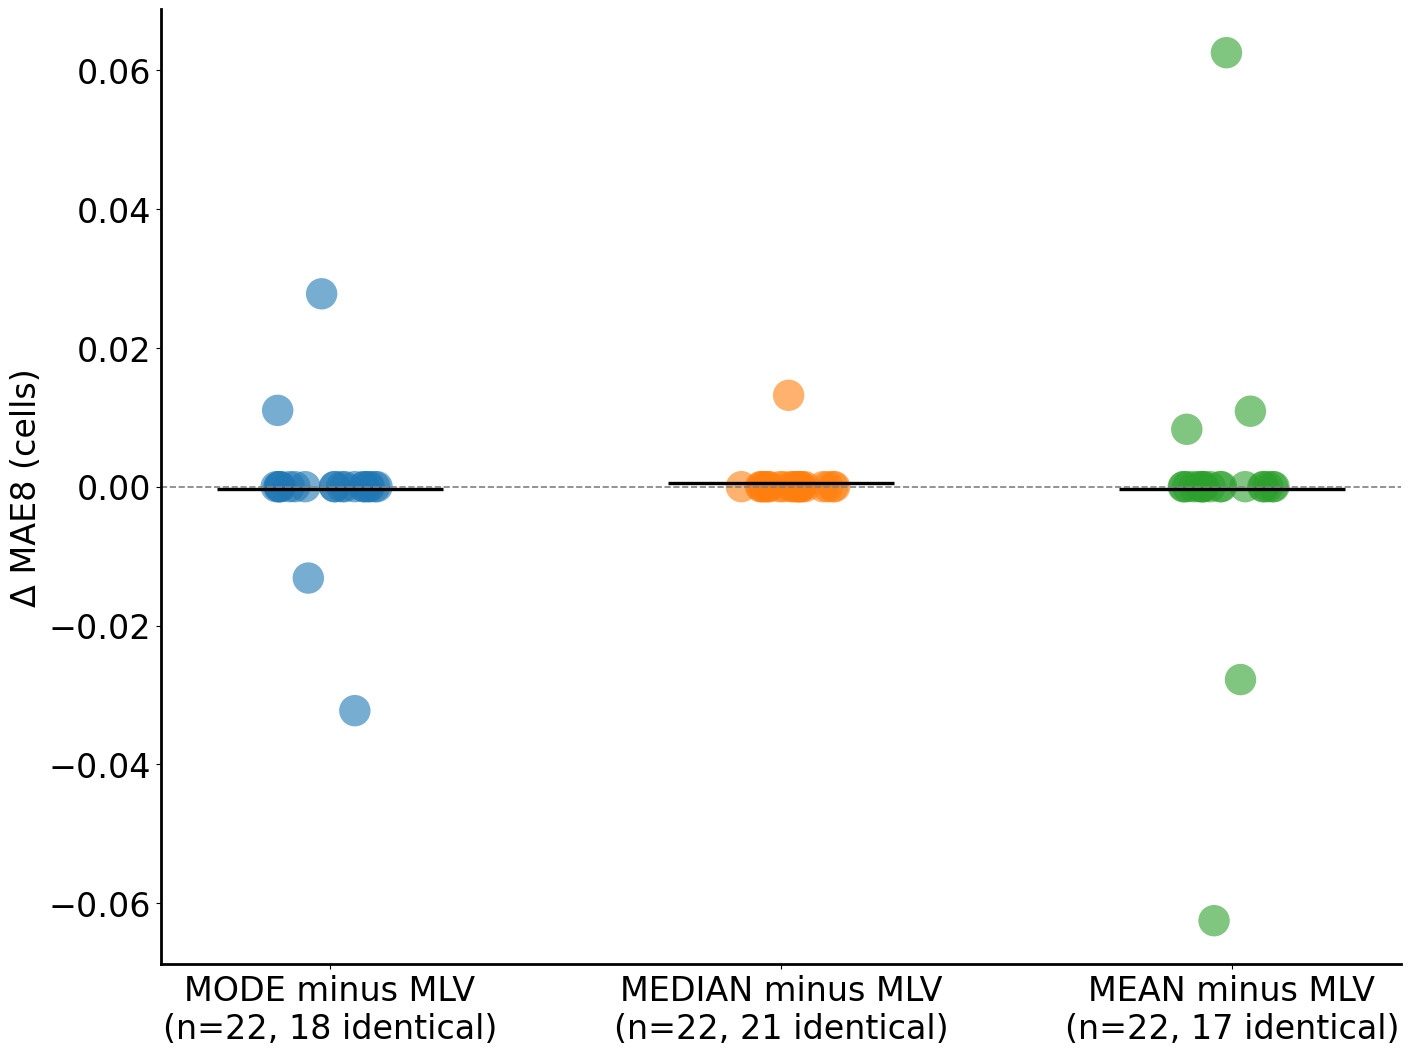

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

scale = 4
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 5*scale, 'axes.labelsize': 6*scale,
    'axes.titlesize': 8*scale, 'xtick.labelsize': 6*scale,
    'ytick.labelsize': 6*scale, 'legend.fontsize': 6*scale,
    'svg.fonttype': 'none',          # keep text editable in the SVG (Illustrator/Inkscape)
    'axes.linewidth': 0.5*scale,
})

others = ["MODE", "MEDIAN", "MEAN"]
diffs = pd.DataFrame({o: mae8[o] - mae8["MLV"] for o in others})

fig, ax = plt.subplots(figsize=(1.6*scale + 1.2*scale*len(others)/3*2, 1.1*scale + 2*scale))
rng = np.random.default_rng(0)
labels = []
for i, o in enumerate(others):
    y = diffs[o].dropna()
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(y)), y,
               s=8*scale**3, alpha=0.6, edgecolors="none")
    ax.hlines(y.mean(), i - 0.25, i + 0.25, color="k", lw=0.6*scale)
    labels.append(f"{o} minus MLV\n(n={len(y)}, {(y == 0).sum()} identical)")

ax.axhline(0, color="grey", ls="--", lw=0.3*scale)
ax.set_xticks(range(len(others)))
ax.set_xticklabels(labels)
ax.set_ylabel("Δ MAE8 (cells)")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

path_save, name_fig = "Figures", "mae8_diff"
os.makedirs(path_save, exist_ok=True)
fig.savefig(os.path.join(path_save, f"{name_fig}.png"), bbox_inches='tight', dpi=300)
fig.savefig(os.path.join(path_save, f"{name_fig}.svg"), bbox_inches='tight')
plt.show()